
# CSCN8000 – Artificial Intelligence Algorithms and Mathematics

## Assignment 1: Parkinson's Disease Prediction

**Student Name:** Asangika Hettiarachchi

**Dataset:** Parkinson's Disease Classification

**Source:** UCI Machine Learning Repository

**Objective:**

The objective of this assignment is to develop machine learning classification models to predict whether a patient has Parkinson's disease using voice measurement features.

The four classification algorithms used are:
1. K-Nearest Neighbors (KNN)
2. Random Forest
3. Support Vector Machine (SVM)
4. Decision Tree



# Question 1 – Data Preprocessing

Perform the following preprocessing steps:

i. Data Analysis

ii. Data Preprocessing

iii. Data Standardization


### i. Data Analysis

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:

# Load the Parkinson's disease dataset

df = pd.read_csv("data/pd_speech_features.csv", header=1)

# Display the first five records
df.head()


,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
0,0,1,0.85247,0.71826,0.57227,240,239,0.008064,0.000087,0.00218,...,1.5620,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405,1
1,0,1,0.76686,0.69481,0.53966,234,233,0.008258,0.000073,0.00195,...,1.5589,3.6107,23.5155,14.1962,11.0261,9.5082,6.5245,6.3431,45.1780,1
2,0,1,0.85083,0.67604,0.58982,232,231,0.008340,0.000060,0.00176,...,1.5643,2.3308,9.4959,10.7458,11.0177,4.8066,2.9199,3.1495,4.7666,1
3,1,0,0.41121,0.79672,0.59257,178,177,0.010858,0.000183,0.00419,...,3.7805,3.5664,5.2558,14.0403,4.2235,4.6857,4.8460,6.2650,4.0603,1
4,1,0,0.32790,0.79782,0.53028,236,235,0.008162,0.002669,0.00535,...,6.1727,5.8416,6.0805,5.7621,7.7817,11.6891,8.2103,5.0559,6.1164,1


In [3]:

# Display the number of rows and columns

print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display dataset information

df.info()


Number of records: 756
Number of columns: 755
<class 'pandas.DataFrame'>
RangeIndex: 756 entries, 0 to 755
Columns: 755 entries, id to class
dtypes: float64(749), int64(6)
memory usage: 4.4 MB


In [4]:

# Count missing values in each column

missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

# Display columns with missing values, if any
print(missing_values[missing_values > 0])





Total missing values: 0
Series([], dtype: int64)


In [5]:
# Generate descriptive statistics

df.describe()

,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
count,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,...,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000
mean,125.500000,0.515873,0.746284,0.700414,0.489058,323.972222,322.678571,0.006360,0.000383,0.002324,...,26.237251,22.840337,18.587888,13.872018,12.218953,12.375335,14.799230,14.751559,31.481110,0.746032
std,72.793721,0.500079,0.169294,0.069718,0.137442,99.219059,99.402499,0.001826,0.000728,0.002628,...,42.220693,32.626464,25.537464,20.046029,17.783642,16.341665,15.722502,14.432979,34.230991,0.435568
min,0.000000,0.000000,0.041551,0.543500,0.154300,2.000000,1.000000,0.002107,0.000011,0.000210,...,1.509800,1.531700,1.582900,1.747200,1.789500,1.628700,1.861700,1.955900,2.364000,0.000000
25%,62.750000,0.000000,0.762833,0.647053,0.386537,251.000000,250.000000,0.005003,0.000049,0.000970,...,2.408675,3.452800,3.354825,3.077450,2.937025,3.114375,3.665925,3.741275,3.948750,0.000000
50%,125.500000,1.000000,0.809655,0.700525,0.484355,317.000000,316.000000,0.006048,0.000077,0.001495,...,5.586300,7.062750,6.077400,4.770850,4.300450,4.741450,6.725700,7.334250,10.637250,1.000000
75%,188.250000,1.000000,0.834315,0.754985,0.586515,384.250000,383.250000,0.007528,0.000171,0.002520,...,28.958075,29.830850,21.944050,13.188000,10.876150,12.201325,21.922050,22.495175,61.125325,1.000000
max,251.000000,1.000000,0.907660,0.852640,0.871230,907.000000,905.000000,0.012966,0.003483,0.027750,...,239.788800,203.311300,121.542900,102.207000,85.571700,73.532200,62.007300,57.544300,156.423700,1.000000


In [6]:

# Examine the target variable

print("Target variable: class")
print("\nClass distribution:")
print(df['class'].value_counts())

print("\nClass percentages:")
print((df['class'].value_counts(normalize=True) * 100).round(2))


Target variable: class

Class distribution:
class
1    564
0    192
Name: count, dtype: int64

Class percentages:
class
1    74.6
0    25.4
Name: proportion, dtype: float64


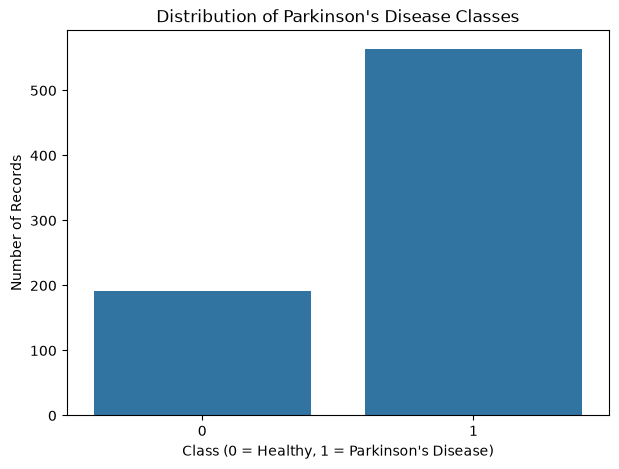

In [7]:

# Visualize the distribution of the target variable

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='class')

plt.title("Distribution of Parkinson's Disease Classes")
plt.xlabel("Class (0 = Healthy, 1 = Parkinson's Disease)")
plt.ylabel("Number of Records")

plt.show()


In [8]:

# Examine unique patient IDs

print("Number of unique patients:", df['id'].nunique())

# Count recordings per patient
print("\nRecordings per patient:")
print(df['id'].value_counts().value_counts().sort_index())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())


Number of unique patients: 252

Recordings per patient:
count
3    252
Name: count, dtype: int64

Duplicate rows: 1



### Data Analysis – Findings and Observations

The initial analysis of the Parkinson's Disease Classification
dataset revealed the following:

1. The dataset contains 756 records and 755 columns.
2. The dataset includes patient identification information,
   gender, voice measurement features, and a target variable
   named `class`.
3. There are no missing values in the dataset.
4. The target variable contains two classes:
   - Class 0: Healthy individuals (192 records, 25.40%).
   - Class 1: Individuals with Parkinson's disease
     (564 records, 74.60%).
5. The dataset contains 252 unique patient IDs, with
   three voice recordings per patient.
6. One duplicate row was identified.

The target distribution shows that the dataset is imbalanced,
with more Parkinson's disease recordings than healthy recordings.

The dataset is suitable for binary classification.
However, the duplicate record and repeated recordings
from the same patients should be considered during
the data preprocessing and model evaluation stages.


### ii. Data Preprocessing

In this step, the dataset is prepared for machine learning by identifying the target variable, removing unnecessary columns, checking duplicate records, and separating the input features from the target variable. The patient ID is not used as a predictive feature because it is an identifier rather than a voice measurement.

In [9]:
# Check the number of duplicate rows
print("Duplicate rows before cleaning:", df.duplicated().sum())

# Remove exact duplicate rows
df_clean = df.drop_duplicates().copy()

# Check the number of duplicate rows after cleaning
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

# Check the new dataset dimensions
print("Dataset shape after removing duplicates:", df_clean.shape)

Duplicate rows before cleaning: 1
Duplicate rows after cleaning: 0
Dataset shape after removing duplicates: (755, 755)


In [10]:
# Check whether each patient has only one class label
patient_class_counts = df_clean.groupby("id")["class"].nunique()

print("Patients with more than one class label:",
      (patient_class_counts > 1).sum())

print("Number of unique patients:", df_clean["id"].nunique())

Patients with more than one class label: 0
Number of unique patients: 252


In [11]:
# Separate input features and target variable
X = df_clean.drop(columns=["id", "class"])
y = df_clean["class"]

# Display the dimensions
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Display the feature columns
print("Number of features:", X.shape[1])
print("Target variable:", y.name)

Features shape: (755, 753)
Target shape: (755,)
Number of features: 753
Target variable: class


In [12]:
# Check for non-numeric columns
print("Non-numeric columns:")
print(X.select_dtypes(exclude=["number"]).columns.tolist())

# Check for infinite values
print("Number of infinite values:", np.isinf(X).sum().sum())

# Display the first five rows of the prepared features
display(X.head())

# Display the target values
display(y.head())

Non-numeric columns:
[]
Number of infinite values: 0


,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,locAbsJitter,...,tqwt_kurtosisValue_dec_27,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36
0,1,0.85247,0.71826,0.57227,240,239,0.008064,0.000087,0.00218,0.000018,...,1.5466,1.5620,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405
1,1,0.76686,0.69481,0.53966,234,233,0.008258,0.000073,0.00195,0.000016,...,1.5530,1.5589,3.6107,23.5155,14.1962,11.0261,9.5082,6.5245,6.3431,45.1780
2,1,0.85083,0.67604,0.58982,232,231,0.008340,0.000060,0.00176,0.000015,...,1.5399,1.5643,2.3308,9.4959,10.7458,11.0177,4.8066,2.9199,3.1495,4.7666
3,0,0.41121,0.79672,0.59257,178,177,0.010858,0.000183,0.00419,0.000046,...,6.9761,3.7805,3.5664,5.2558,14.0403,4.2235,4.6857,4.8460,6.2650,4.0603
4,0,0.32790,0.79782,0.53028,236,235,0.008162,0.002669,0.00535,0.000044,...,7.8832,6.1727,5.8416,6.0805,5.7621,7.7817,11.6891,8.2103,5.0559,6.1164


0    1
1    1
2    1
3    1
4    1
Name: class, dtype: int64

**Data Preprocessing – Findings**

- One exact duplicate record was identified and removed.
- The cleaned dataset contains 755 records.
- The patient ID (`id`) is excluded from the input features because it is an identifier and does not represent a voice measurement.
- The `class` column is separated as the target variable.
- The remaining columns, including `gender` and the voice measurements, are used as input features.
- Patient IDs and their class labels are checked to identify any patients with inconsistent labels.
- The input feature dataset (X) contains 755 records and 753 features.
- The target variable (y) contains 755 class labels.

The prepared features and target variable are now ready for the next stage, data standardization.

### iii. Data Standardization

Data standardization is the process of transforming numerical features so that they have a mean of approximately 0 and a standard deviation of approximately 1.

This step is important for machine learning algorithms such as K-Nearest Neighbors (KNN) and Support Vector Machine (SVM), because these algorithms are sensitive to differences in feature scales.

For this assignment, the `StandardScaler` from Scikit-learn will be used.

To prevent data leakage, the scaler will be fitted using only the training data. The same scaler will then be applied to the testing data.

# Question 2 – Training and Testing Data Split

The dataset is divided into 80% training data and 20% testing data.

Since the dataset contains three voice recordings for each patient, the split is performed at the patient level. This ensures that recordings from the same patient do not appear in both the training and testing datasets.

The patient IDs are used only to perform the split and are not included as model input features.

### Split the data set

In [13]:
from sklearn.model_selection import train_test_split

# Create a summary containing one record per patient
patient_summary = df_clean.groupby("id", as_index=False)["class"].first()

# Split patient IDs into training and testing groups
train_patient_ids, test_patient_ids = train_test_split(
    patient_summary["id"],
    test_size=0.20,
    random_state=42,
    stratify=patient_summary["class"]
)

# Identify the recordings belonging to each patient group
train_mask = df_clean["id"].isin(train_patient_ids)
test_mask = df_clean["id"].isin(test_patient_ids)

# Create training and testing datasets
X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

# Display dataset dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (602, 753)
Testing features: (153, 753)
Training target: (602,)
Testing target: (153,)


In [14]:
# Calculate the percentage of training and testing records
total_records = len(X_train) + len(X_test)

train_percentage = (len(X_train) / total_records) * 100
test_percentage = (len(X_test) / total_records) * 100

print("Total records:", total_records)

print("\nTraining records:", len(X_train))
print("Training percentage:", round(train_percentage, 2), "%")

print("\nTesting records:", len(X_test))
print("Testing percentage:", round(test_percentage, 2), "%")

Total records: 755

Training records: 602
Training percentage: 79.74 %

Testing records: 153
Testing percentage: 20.26 %


In [15]:
# Check whether any patient appears in both datasets
train_ids = set(train_patient_ids)
test_ids = set(test_patient_ids)

overlapping_patients = train_ids.intersection(test_ids)

print("Training patients:", len(train_ids))
print("Testing patients:", len(test_ids))
print("Overlapping patients:", len(overlapping_patients))

Training patients: 201
Testing patients: 51
Overlapping patients: 0


In [16]:
print("Training class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training class distribution:
class
0    153
1    449
Name: count, dtype: int64

Testing class distribution:
class
0     39
1    114
Name: count, dtype: int64


### Apply standardization

In [17]:
from sklearn.preprocessing import StandardScaler

# Create the StandardScaler object
scaler = StandardScaler()

# Fit the scaler using training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaler to testing data
X_test_scaled = scaler.transform(X_test)

# Convert scaled arrays back to DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

print("Standardized training data:", X_train_scaled.shape)
print("Standardized testing data:", X_test_scaled.shape)

Standardized training data: (602, 753)
Standardized testing data: (153, 753)


In [18]:
# Check the mean and standard deviation of standardized training features
print("Mean of standardized training features:")
print(X_train_scaled.mean().head())

print("\nStandard deviation of standardized training features:")
print(X_train_scaled.std(ddof=0).head())

Mean of standardized training features:
gender      -7.081821e-17
PPE          2.006516e-16
DFA         -7.435912e-16
RPDE        -5.193336e-16
numPulses   -2.360607e-16
dtype: float64

Standard deviation of standardized training features:
gender       1.0
PPE          1.0
DFA          1.0
RPDE         1.0
numPulses    1.0
dtype: float64


**Question 2 – Findings and Observations**

The dataset was divided into training and testing sets using an 80/20 split at the patient level.

- Training dataset: 602 records (79.74%).
- Testing dataset: 153 records (20.26%).
- Training patients: 201.
- Testing patients: 51.
- No patient IDs were shared between the training and testing datasets.
- Stratification was applied to maintain the class distribution in both datasets.

StandardScaler was fitted using only the training data and then applied to both the training and testing datasets. This prevents data leakage during model development.

The training and testing datasets are now prepared for machine learning model training.

# Question 3 – Model Training

In this question, four machine learning classification algorithms are trained using the training dataset.

The following algorithms are implemented:

1. **K-Nearest Neighbors (KNN):** Classifies a sample based on the nearest data points.
2. **Random Forest:** Uses multiple decision trees to improve classification performance.
3. **Support Vector Machine (SVM):** Finds an optimal decision boundary to separate the classes.
4. **Decision Tree:** Uses a tree-like structure of decisions to classify the data.

The standardized training features (`X_train_scaled`) and training target (`y_train`) are used to train the models.

### 3.1 K-Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) is a supervised machine learning algorithm used for classification. It classifies a new data point based on the majority class of its nearest neighbors.

For this assignment, the KNN model is trained using the standardized training features and their corresponding target labels.

The number of neighbors (`n_neighbors`) is set to 5.

In [19]:

from sklearn.neighbors import KNeighborsClassifier

# Create the KNN classifier
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the KNN model
knn_model.fit(X_train_scaled, y_train)

print("KNN model trained successfully.")


KNN model trained successfully.


### 3.2 Random Forest

Random Forest is a supervised machine learning algorithm used for classification. It builds multiple decision trees and combines their predictions to produce the final classification.

For this assignment, the Random Forest model is trained using the standardized training features (`X_train_scaled`) and their corresponding target labels (`y_train`).

The model uses 100 decision trees (`n_estimators=100`). A random state of 42 is used to make the results reproducible.

In [20]:

from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the Random Forest model
rf_model.fit(X_train_scaled, y_train)

print("Random Forest model trained successfully.")


Random Forest model trained successfully.


### 3.3 Support Vector Machine (SVM)

Support Vector Machine (SVM) is a supervised machine learning algorithm used for classification. It finds the best boundary (hyperplane) to separate different classes.

For this assignment, the SVM model is trained using the standardized training features (`X_train_scaled`) and their corresponding target labels (`y_train`).

The Radial Basis Function (RBF) kernel is used to handle possible non-linear relationships in the data.

In [21]:
from sklearn.svm import SVC

# Create the SVM classifier
svm_model = SVC(kernel="rbf", random_state=42)

# Train the SVM model
svm_model.fit(X_train_scaled, y_train)

print("SVM model trained successfully.")

SVM model trained successfully.


### 3.4 Decision Tree

Decision Tree is a supervised machine learning algorithm used for classification. It makes predictions by splitting the data into smaller groups based on feature values. Each split helps the model decide which class a sample belongs to.

For this assignment, the Decision Tree model is trained using the standardized training features (`X_train_scaled`) and their corresponding target labels (`y_train`).

A random state of 42 is used to make the results reproducible.

In [22]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree classifier
dt_model = DecisionTreeClassifier(random_state=42)

# Train the Decision Tree model
dt_model.fit(X_train_scaled, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


## Question 4 – Predict the Class on Test Data

In this question, the trained machine learning models are used to predict the class of the test data.

The predictions are generated using the following four models:
1. K-Nearest Neighbors (KNN)
2. Random Forest
3. Support Vector Machine (SVM)
4. Decision Tree

The standardized test features (`X_test_scaled`) are provided to each model to predict whether each patient sample belongs to class 0 or class 1.

In [23]:
# Generate predictions using all four trained models

# KNN predictions
knn_predictions = knn_model.predict(X_test_scaled)

# Random Forest predictions
rf_predictions = rf_model.predict(X_test_scaled)

# SVM predictions
svm_predictions = svm_model.predict(X_test_scaled)

# Decision Tree predictions
dt_predictions = dt_model.predict(X_test_scaled)

print("Predictions generated successfully for all four models.")

Predictions generated successfully for all four models.


In [24]:
# Display the first 10 predictions from each model

print("KNN Predictions:", knn_predictions[:10])
print("Random Forest Predictions:", rf_predictions[:10])
print("SVM Predictions:", svm_predictions[:10])
print("Decision Tree Predictions:", dt_predictions[:10])

# Check the number of predictions
print("\nNumber of test samples:", len(y_test))
print("KNN predictions:", len(knn_predictions))
print("Random Forest predictions:", len(rf_predictions))
print("SVM predictions:", len(svm_predictions))
print("Decision Tree predictions:", len(dt_predictions))

KNN Predictions: [1 1 1 1 1 0 1 0 0 1]
Random Forest Predictions: [1 1 1 1 1 1 1 1 1 1]
SVM Predictions: [1 1 1 1 1 1 1 1 1 1]
Decision Tree Predictions: [1 1 0 1 1 1 1 1 1 1]

Number of test samples: 153
KNN predictions: 153
Random Forest predictions: 153
SVM predictions: 153
Decision Tree predictions: 153


## Question 5 – Build a Predictive System

In this question, a predictive system is developed to verify that the trained machine learning models can predict Parkinson's disease for a new sample.

A sample from the test dataset is selected to simulate a new patient sample. The existing StandardScaler is used to standardize the sample, and all four trained models generate predictions.

The predicted classes are:
- Class 0: Healthy
- Class 1: Parkinson's disease

This demonstrates how the trained models can be used to make predictions for an individual patient sample.

In [25]:
# Build a predictive system using one sample from the test dataset

# Select one sample to simulate a new patient
new_sample = X_test.iloc[[0]]

# Standardize the sample using the existing scaler
new_sample_scaled = scaler.transform(new_sample)

# Convert the standardized sample back to a DataFrame
new_sample_scaled = pd.DataFrame(
    new_sample_scaled,
    columns=X_test.columns
)

# Generate predictions using all four trained models
knn_result = knn_model.predict(new_sample_scaled)[0]
rf_result = rf_model.predict(new_sample_scaled)[0]
svm_result = svm_model.predict(new_sample_scaled)[0]
dt_result = dt_model.predict(new_sample_scaled)[0]

# Function to display the predicted class
def display_prediction(prediction):
    if prediction == 0:
        return "Class 0 - Healthy"
    else:
        return "Class 1 - Parkinson's Disease"

# Display the predictions
print("Predictive System Results")
print("-------------------------")
print("KNN Prediction:", display_prediction(knn_result))
print("Random Forest Prediction:", display_prediction(rf_result))
print("SVM Prediction:", display_prediction(svm_result))
print("Decision Tree Prediction:", display_prediction(dt_result))

Predictive System Results
-------------------------
KNN Prediction: Class 1 - Parkinson's Disease
Random Forest Prediction: Class 1 - Parkinson's Disease
SVM Prediction: Class 1 - Parkinson's Disease
Decision Tree Prediction: Class 1 - Parkinson's Disease


**Predictive System – Findings**

- A sample from the test dataset was selected to simulate a new patient.
- The existing StandardScaler was used to standardize the sample.
- All four trained models successfully generated a prediction.
- KNN, Random Forest, SVM, and Decision Tree all predicted Class 1 (Parkinson's Disease) for the selected sample.

The results demonstrate that all four trained models can be used to predict the class of an individual sample.

## Question 6 – Model Evaluation

In this question, the performance of the four trained machine learning models is evaluated using the test dataset.

The following evaluation metrics are used:

- **Accuracy:** Measures the overall percentage of correctly predicted samples.
- **Confusion Matrix:** Shows the number of correct and incorrect predictions for each class.
- **Classification Report:** Provides precision, recall, F1-score, and support for each class.

The four models are compared to identify the model with the highest accuracy.

In [26]:
from sklearn.metrics import accuracy_score

# Calculate accuracy for all four models
accuracies_models = pd.DataFrame({
    'knn_accuracy': [accuracy_score(y_test, knn_predictions)],
    'rf_accuracy': [accuracy_score(y_test, rf_predictions)],
    'svm_accuracy': [accuracy_score(y_test, svm_predictions)],
    'dt_accuracy': [accuracy_score(y_test, dt_predictions)]
})

# Display the accuracy comparison
display(accuracies_models)

,knn_accuracy,rf_accuracy,svm_accuracy,dt_accuracy
0,0.751634,0.803922,0.803922,0.732026


In [27]:
from sklearn.metrics import confusion_matrix, classification_report

# Store predictions from all four models
model_predictions = {
    "KNN": knn_predictions,
    "Random Forest": rf_predictions,
    "SVM": svm_predictions,
    "Decision Tree": dt_predictions
}

# Display confusion matrix and classification report for each model
for model_name, predictions in model_predictions.items():

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    # Confusion Matrix
    cm = confusion_matrix(y_test, predictions)

    print("\nConfusion Matrix:")
    print(cm)

    # Classification Report
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=["Healthy (Class 0)", "Parkinson's Disease (Class 1)"]
    ))


KNN

Confusion Matrix:
[[ 14  25]
 [ 13 101]]

Classification Report:
                               precision    recall  f1-score   support

            Healthy (Class 0)       0.52      0.36      0.42        39
Parkinson's Disease (Class 1)       0.80      0.89      0.84       114

                     accuracy                           0.75       153
                    macro avg       0.66      0.62      0.63       153
                 weighted avg       0.73      0.75      0.74       153


Random Forest

Confusion Matrix:
[[ 15  24]
 [  6 108]]

Classification Report:
                               precision    recall  f1-score   support

            Healthy (Class 0)       0.71      0.38      0.50        39
Parkinson's Disease (Class 1)       0.82      0.95      0.88       114

                     accuracy                           0.80       153
                    macro avg       0.77      0.67      0.69       153
                 weighted avg       0.79      0.80      0.78  

**Model Evaluation – Findings**

- KNN achieved an accuracy of 75.16%.
- Random Forest achieved an accuracy of 80.39%.
- SVM achieved an accuracy of 80.39%.
- Decision Tree achieved an accuracy of 73.20%.
- Random Forest and SVM achieved the highest accuracy of 80.39%.
- The confusion matrices and classification reports show that all four models performed better at identifying Parkinson's disease samples than healthy samples.
- Random Forest correctly classified 108 Parkinson's disease samples, while SVM correctly classified 109.
- The results indicate that accuracy alone is not sufficient to evaluate model performance. Precision, recall, and F1-score should also be considered.

**Conclusion:** Random Forest and SVM are the top-performing models based on accuracy. However, both models have difficulty identifying healthy samples. Further evaluation of recall and other classification metrics is important before considering either model suitable for medical decision support.

## Question 7 – Save Test Predictions in a CSV File

In this question, the actual test class and the predicted classes from all four trained machine learning models are saved in a single CSV file.

The CSV file includes:
- Patient ID
- Actual class
- KNN predicted class
- Random Forest predicted class
- SVM predicted class
- Decision Tree predicted class

This file allows us to compare the actual classes with the predictions generated by each model.

In [28]:
# Create a DataFrame containing actual and predicted classes

predictions_df = pd.DataFrame({
    "Patient_ID": df_clean.loc[X_test.index, "id"].values,
    "Actual_Class": y_test.values,
    "KNN_Prediction": knn_predictions,
    "Random_Forest_Prediction": rf_predictions,
    "SVM_Prediction": svm_predictions,
    "Decision_Tree_Prediction": dt_predictions
})

# Save all predictions in one CSV file
predictions_df.to_csv("Parkinsons_Test_Predictions.csv", index=False)

print("Test predictions saved successfully.")

# Display the first 10 rows
display(predictions_df.head(10))

Test predictions saved successfully.


,Patient_ID,Actual_Class,KNN_Prediction,Random_Forest_Prediction,SVM_Prediction,Decision_Tree_Prediction
0,1,1,1,1,1,1
1,1,1,1,1,1,1
2,1,1,1,1,1,0
3,3,1,1,1,1,1
4,3,1,1,1,1,1
5,3,1,0,1,1,1
6,8,1,1,1,1,1
7,8,1,0,1,1,1
8,8,1,0,1,1,1
9,15,1,1,1,1,1


In [29]:
# Verify the saved CSV file

saved_predictions = pd.read_csv("Parkinsons_Test_Predictions.csv")

print("CSV file loaded successfully.")
print("Number of records:", len(saved_predictions))
print("Number of columns:", len(saved_predictions.columns))

display(saved_predictions.head())

CSV file loaded successfully.
Number of records: 153
Number of columns: 6


,Patient_ID,Actual_Class,KNN_Prediction,Random_Forest_Prediction,SVM_Prediction,Decision_Tree_Prediction
0,1,1,1,1,1,1
1,1,1,1,1,1,1
2,1,1,1,1,1,0
3,3,1,1,1,1,1
4,3,1,1,1,1,1


**Test Predictions – Findings**

- The actual test classes and predictions from all four machine learning models were saved in one CSV file.
- The CSV file contains the patient ID, actual class, and predicted class from each model.
- A total of 153 test records were saved.
- The saved file can be used to compare the predictions of the four models.

**Conclusion:** All four machine learning models successfully generated predictions, and their results were saved in a single CSV file for further comparison.